# Сравнение моделей SegFormer B0 и SegFormer B5

Монтируем диск

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
from google.colab import output
!pip install torch torchvision transformers pillow matplotlib datasets accelerate pandas tqdm gdown
output.clear()
print("Dependencies installed")

Dependencies installed


# Скачивание датасета

Структура директорий:

segmentation

|- test_seg.ipynb

|- gtFine_trainvaltest.zip

In [4]:
!unzip "/content/drive/MyDrive/segmentation/gtFine_trainvaltest.zip" -d "/content/dataset"
output.clear()

### Визуализация одного сэмпла

Скачиваем только val часть

In [5]:
from datasets import load_dataset
import numpy as np
import matplotlib.pyplot as plt

Keys: dict_keys(['image', 'semantic_segmentation'])
Image size: (2048, 1024)
Mask size: (2048, 1024)


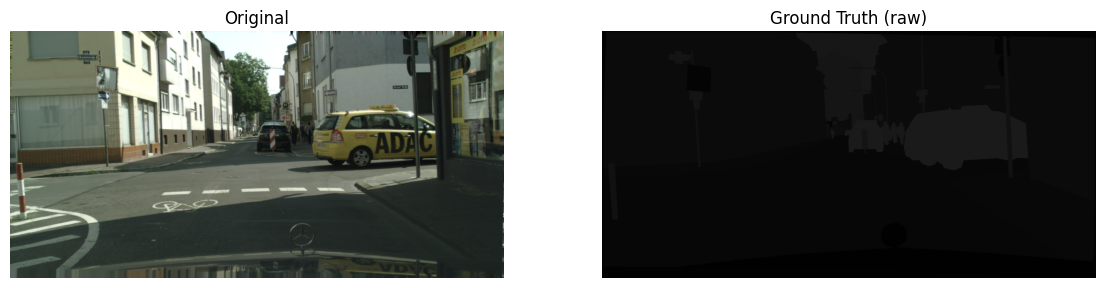

GT values: [ 1  2  3  4  7  8 11 13 17 20 21 23 24 26]


In [7]:
dataset = load_dataset(
    "Chris1/cityscapes",
    split="validation",
    streaming=True
)

sample = next(iter(dataset))

print("Keys:", sample.keys())

image = sample["image"]
gt_image = sample["semantic_segmentation"]

print("Image size:", image.size)
print("Mask size:", gt_image.size)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].imshow(image)
axes[0].set_title("Original")
axes[0].axis("off")

axes[1].imshow(gt_image)
axes[1].set_title("Ground Truth (raw)")
axes[1].axis("off")

plt.show()

print("GT values:", np.unique(np.asarray(gt_image)))

In [9]:
!pip -q install cityscapesscripts

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


{7: 0, 8: 1, 11: 2, 12: 3, 13: 4, 17: 5, 19: 6, 20: 7, 21: 8, 22: 9, 23: 10, 24: 11, 25: 12, 26: 13, 27: 14, 28: 15, 31: 16, 32: 17, 33: 18}


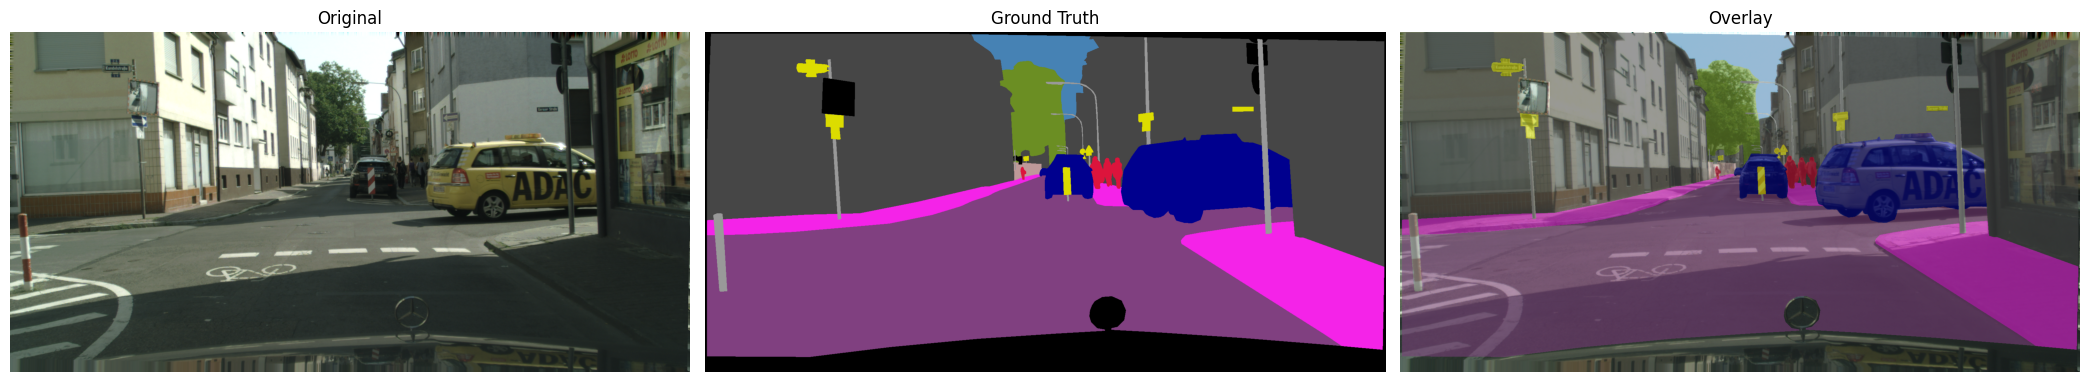

In [10]:
from cityscapesscripts.helpers.labels import labels

original = np.array(image.convert("RGB"))
gt_raw = np.array(gt_image)[:, :, 0]

id_to_trainid = {
    label.id: label.trainId
    for label in labels
    if 0 <= label.trainId < 19
}

print(id_to_trainid)

gt = np.full(gt_raw.shape, 255, dtype=np.uint8)

for label_id, train_id in id_to_trainid.items():
    gt[gt_raw == label_id] = train_id

# Cityscapes palette
palette = np.array([
    [128, 64, 128], [244, 35, 232], [70, 70, 70],
    [102, 102, 156], [190, 153, 153], [153, 153, 153],
    [250, 170, 30], [220, 220, 0], [107, 142, 35],
    [152, 251, 152], [70, 130, 180], [220, 20, 60],
    [255, 0, 0], [0, 0, 142], [0, 0, 70],
    [0, 60, 100], [0, 80, 100], [0, 0, 230],
    [119, 11, 32]
], dtype=np.uint8)

# colorful mask
valid = gt != 255
color_mask = np.zeros_like(original)
color_mask[valid] = palette[gt[valid]]

overlay = original.copy()
overlay[valid] = (
    0.45 * original[valid] + 0.55 * color_mask[valid]
).astype(np.uint8)

# visualizing
fig, axes = plt.subplots(1, 3, figsize=(21, 7))

for ax, img, title in zip(
    axes,
    [original, color_mask, overlay],
    ["Original", "Ground Truth", "Overlay"]
):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

### Подсчет статистик для B0, B5

In [11]:
import gc
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import islice
from tqdm.auto import tqdm
from datasets import load_dataset
from transformers import AutoImageProcessor, SegformerForSemanticSegmentation
from IPython.display import display
from pathlib import Path

Loading B0...


preprocessor_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 15.0MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  339MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]


RESULTS
               Metric  Percent
    Pixel accuracy B0   94.587
    Pixel accuracy B5   95.785
              mIoU B0   68.318
              mIoU B5   76.554
      Correction rate    2.363
           Fix recall   43.656
            Harm rate    1.165
             Net gain    1.199
Oracle pixel accuracy   96.950

PER CLASS
        class  IoU_B0  IoU_B5  fixed_pixels  harmed_pixels  delta_IoU  fix_recall
         road  0.9762  0.9821       2013356        1128161     0.0059      0.4267
     sidewalk  0.8202  0.8584       2493800        1455582     0.0382      0.4553
     building  0.8954  0.9189       2863388        2943470     0.0234      0.3757
         wall  0.4773  0.5961       1352650         524583     0.1187      0.4299
        fence  0.4854  0.5993        878200         466893     0.1139      0.3350
         pole  0.4683  0.5677       2528297         495722     0.0994      0.4594
traffic light  0.5281  0.6530        376548          63025     0.1249      0.5091
 traffic sign 

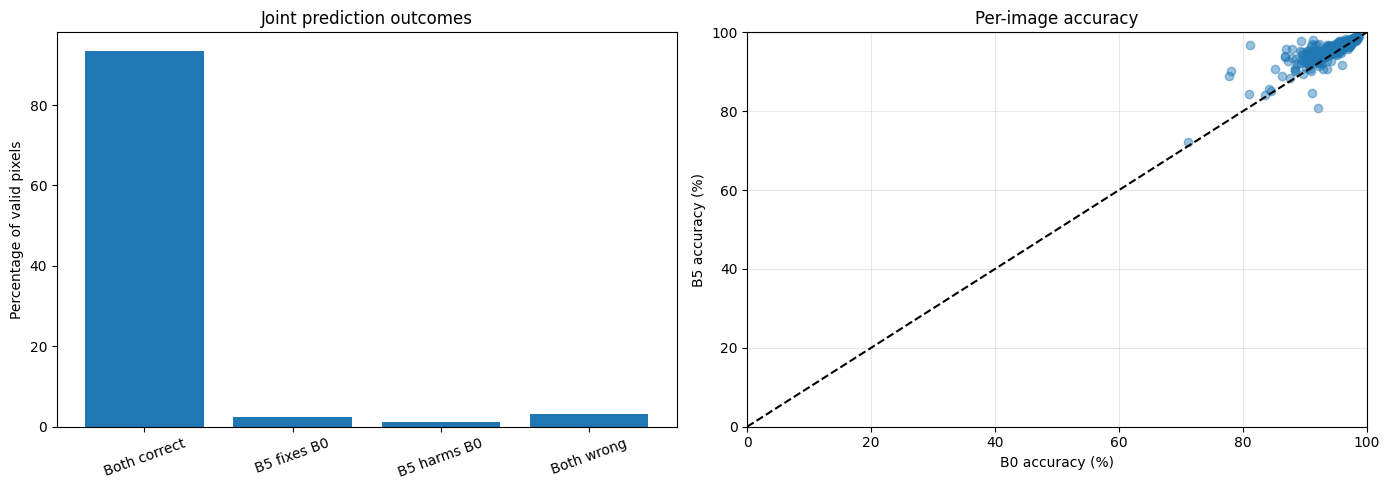

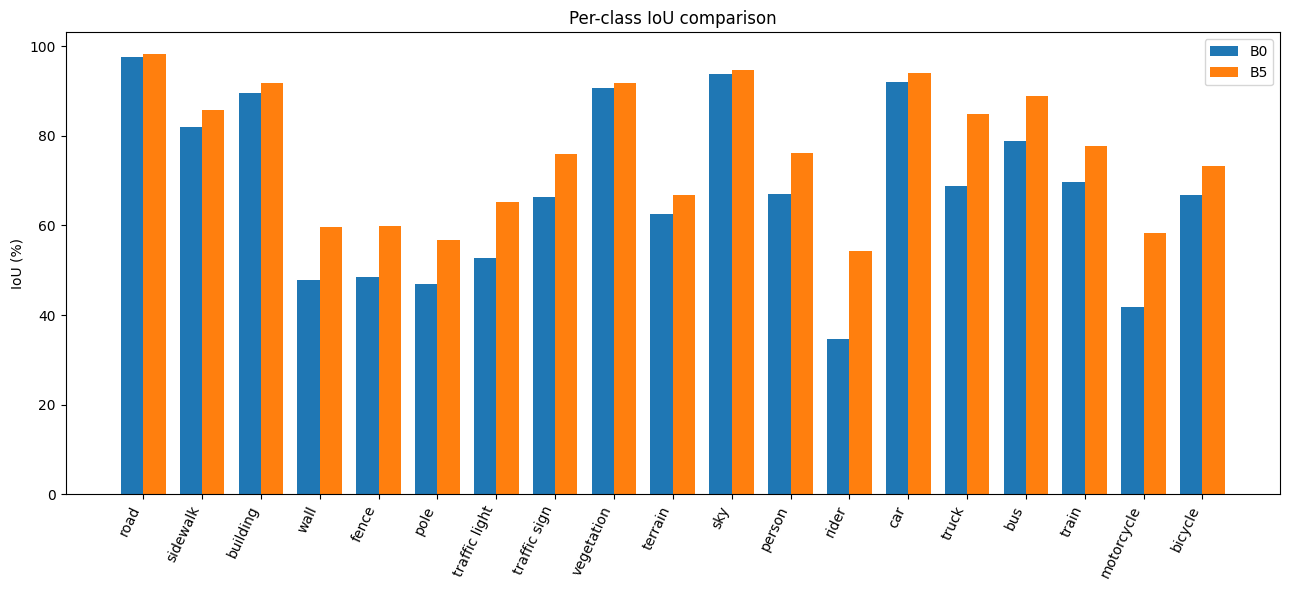

In [12]:
N_IMAGES = 500
N_CLASSES = 19
device = "cuda" if torch.cuda.is_available() else "cpu"

model_ids = {
    "B0": "nvidia/segformer-b0-finetuned-cityscapes-1024-1024",
    "B5": "nvidia/segformer-b5-finetuned-cityscapes-1024-1024",
}

class_names = [
    "road", "sidewalk", "building", "wall", "fence",
    "pole", "traffic light", "traffic sign",
    "vegetation", "terrain", "sky", "person",
    "rider", "car", "truck", "bus", "train",
    "motorcycle", "bicycle"
]

lookup = np.full(256, 255, dtype=np.uint8)

for label_id, train_id in id_to_trainid.items():
    lookup[label_id] = train_id

def prepare_gt(mask):
    raw = np.asarray(mask)[:, :, 0]
    return lookup[raw]

processors = {}
models = {}

for name, model_id in model_ids.items():
    print(f"Loading {name}...")

    processors[name] = AutoImageProcessor.from_pretrained(model_id)

    models[name] = SegformerForSemanticSegmentation.from_pretrained(
        model_id
    ).to(device).eval()

def predict(name, image):
    inputs = processors[name](
        images=image,
        return_tensors="pt",
        do_resize=False
    ).to(device)

    with torch.inference_mode():
        outputs = models[name](**inputs)

        pred = processors[name].post_process_semantic_segmentation(
            outputs,
            target_sizes=[(image.height, image.width)]
        )[0]

    return pred.cpu().numpy()

confusions = {
    name: np.zeros((19, 19), dtype=np.int64)
    for name in models
}

total = {
    "both_correct": 0,
    "fixed": 0,
    "harmed": 0,
    "both_wrong": 0
}

class_fixed = np.zeros(19, dtype=np.int64)
class_harmed = np.zeros(19, dtype=np.int64)
class_light_errors = np.zeros(19, dtype=np.int64)

rows = []

def update_confusion(cm, gt, pred):
    indices = gt.astype(np.int64) * 19 + pred.astype(np.int64)
    cm += np.bincount(indices, minlength=361).reshape(19, 19)

def calculate_iou(cm):
    intersection = np.diag(cm)
    union = cm.sum(0) + cm.sum(1) - intersection

    return np.divide(
        intersection, union,
        out=np.full(19, np.nan),
        where=union > 0
    )

dataset = load_dataset(
    "Chris1/cityscapes",
    split="validation",
    streaming=True
)

for idx, sample in enumerate(
    tqdm(islice(dataset, N_IMAGES), total=N_IMAGES)
):
    image = sample["image"].convert("RGB")
    model_image = image.resize((1024, 1024))

    gt = prepare_gt(sample["semantic_segmentation"])

    light = predict("B0", model_image)
    heavy = predict("B5", model_image)

    light = np.array(
        __import__("PIL").Image.fromarray(light.astype(np.uint8))
        .resize(image.size, resample=0)
    )
    heavy = np.array(
        __import__("PIL").Image.fromarray(heavy.astype(np.uint8))
        .resize(image.size, resample=0)
    )

    valid = gt != 255
    n = valid.sum()

    lc = light == gt
    hc = heavy == gt

    both_correct = valid & lc & hc
    fixed = valid & ~lc & hc
    harmed = valid & lc & ~hc
    both_wrong = valid & ~lc & ~hc

    counts = {
        "both_correct": both_correct.sum(),
        "fixed": fixed.sum(),
        "harmed": harmed.sum(),
        "both_wrong": both_wrong.sum()
    }

    for key in total:
        total[key] += counts[key]

    update_confusion(confusions["B0"], gt[valid], light[valid])
    update_confusion(confusions["B5"], gt[valid], heavy[valid])

    light_errors = valid & ~lc

    class_fixed += np.bincount(gt[fixed], minlength=19)
    class_harmed += np.bincount(gt[harmed], minlength=19)
    class_light_errors += np.bincount(gt[light_errors], minlength=19)

    rows.append({
        "image_id": idx,
        "B0_accuracy": lc[valid].mean(),
        "B5_accuracy": hc[valid].mean(),
        "correction_rate": counts["fixed"] / n,
        "fix_recall": counts["fixed"] / max(light_errors.sum(), 1),
        "harm_rate": counts["harmed"] / n,
        "net_gain": (counts["fixed"] - counts["harmed"]) / n
    })

n = sum(total.values())

iou_b0 = calculate_iou(confusions["B0"])
iou_b5 = calculate_iou(confusions["B5"])

summary_df = pd.DataFrame({
    "Metric": [
        "Pixel accuracy B0",
        "Pixel accuracy B5",
        "mIoU B0",
        "mIoU B5",
        "Correction rate",
        "Fix recall",
        "Harm rate",
        "Net gain",
        "Oracle pixel accuracy"
    ],
    "Percent": [
        100 * (total["both_correct"] + total["harmed"]) / n,
        100 * (total["both_correct"] + total["fixed"]) / n,
        100 * np.nanmean(iou_b0),
        100 * np.nanmean(iou_b5),
        100 * total["fixed"] / n,
        100 * total["fixed"] / (total["fixed"] + total["both_wrong"]),
        100 * total["harmed"] / n,
        100 * (total["fixed"] - total["harmed"]) / n,
        100 * (1 - total["both_wrong"] / n)
    ]
})

df = pd.DataFrame(rows)

print("\nRESULTS")
print(summary_df.round(3).to_string(index=False))

class_df = pd.DataFrame({
    "class": class_names,
    "IoU_B0": iou_b0,
    "IoU_B5": iou_b5,
    "fixed_pixels": class_fixed,
    "harmed_pixels": class_harmed
})

class_df["delta_IoU"] = class_df["IoU_B5"] - class_df["IoU_B0"]

class_df["fix_recall"] = np.divide(
    class_fixed,
    class_light_errors,
    out=np.full(19, np.nan),
    where=class_light_errors > 0
)

print("\nPER CLASS")
print(class_df.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

categories = [
    "Both correct",
    "B5 fixes B0",
    "B5 harms B0",
    "Both wrong"
]

values = [total[key] / n * 100 for key in total]

axes[0].bar(categories, values)
axes[0].set_ylabel("Percentage of valid pixels")
axes[0].set_title("Joint prediction outcomes")
axes[0].tick_params(axis="x", rotation=20)

axes[1].scatter(
    df["B0_accuracy"] * 100,
    df["B5_accuracy"] * 100,
    alpha=0.45
)
axes[1].plot([0, 100], [0, 100], "k--")
axes[1].set_xlim(0, 100)
axes[1].set_ylim(0, 100)
axes[1].set_xlabel("B0 accuracy (%)")
axes[1].set_ylabel("B5 accuracy (%)")
axes[1].set_title("Per-image accuracy")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 6))

x = np.arange(19)
w = 0.38

ax.bar(x - w/2, iou_b0 * 100, w, label="B0")
ax.bar(x + w/2, iou_b5 * 100, w, label="B5")

ax.set_xticks(x)
ax.set_xticklabels(class_names, rotation=65, ha="right")
ax.set_ylabel("IoU (%)")
ax.set_title("Per-class IoU comparison")
ax.legend()

plt.tight_layout()
plt.show()

df.to_csv("per_image_statistics.csv", index=False)
summary_df.to_csv("summary_statistics.csv", index=False)
class_df.to_csv("per_class_statistics.csv", index=False)

### Скорость инференса

Device: cuda
GPU: Tesla T4

===== SegFormer-B0 =====


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Input shape: torch.Size([1, 3, 1024, 1024])
Parameters: 3.72 M
Mean latency:   75.98 ms
Median latency: 75.77 ms
P90 latency:    78.83 ms
FPS:            13.16
Peak GPU memory: 970.4 MB

===== SegFormer-B5 =====


Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

Input shape: torch.Size([1, 3, 1024, 1024])
Parameters: 84.61 M
Mean latency:   565.36 ms
Median latency: 566.36 ms
P90 latency:    571.41 ms
FPS:            1.77
Peak GPU memory: 2447.4 MB

===== BENCHMARK RESULTS =====
       Model  Parameters (M)  Mean latency (ms)  Median latency (ms)  P90 latency (ms)   FPS  Peak GPU memory (MB)        Input shape
SegFormer-B0            3.72              75.98                75.77             78.83 13.16                970.36 (1, 3, 1024, 1024)
SegFormer-B5           84.61             565.36               566.36            571.41  1.77               2447.36 (1, 3, 1024, 1024)

B5 is 7.44x slower than B0


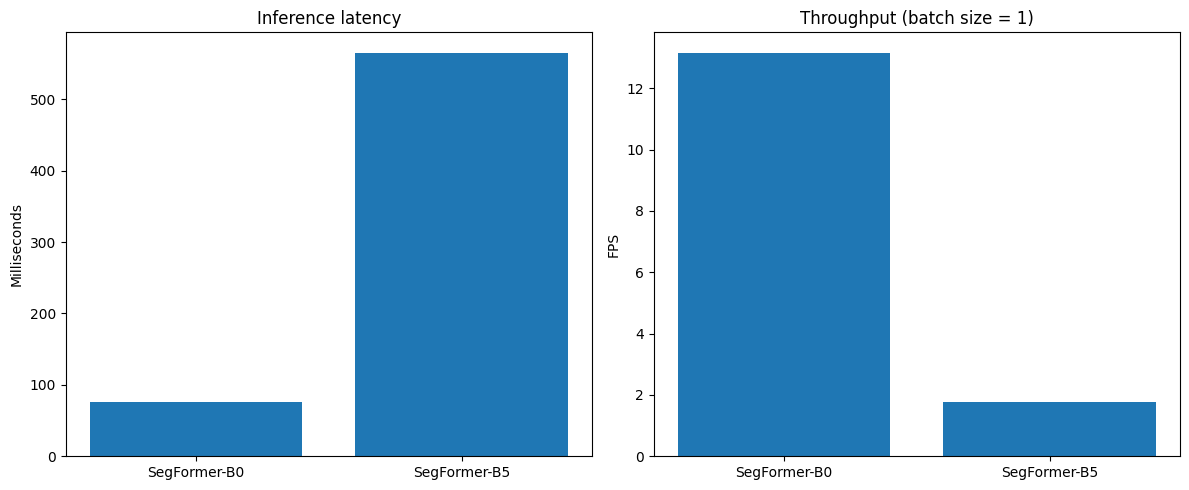

In [14]:
from PIL import Image
import time

device = "cuda" if torch.cuda.is_available() else "cpu"

N_WARMUP = 10
N_RUNS = 30

MODEL_IDS = {
    "SegFormer-B0": "nvidia/segformer-b0-finetuned-cityscapes-1024-1024",
    "SegFormer-B5": "nvidia/segformer-b5-finetuned-cityscapes-1024-1024",
}

print("Device:", device)

if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

test_image = image.convert("RGB")

results = []

def sync_gpu():
    if device == "cuda":
        torch.cuda.synchronize()

for name, model_id in MODEL_IDS.items():

    print(f"\n===== {name} =====")

    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()

    processor = AutoImageProcessor.from_pretrained(model_id)

    model = SegformerForSemanticSegmentation.from_pretrained(
        model_id
    ).to(device).eval()

    params = sum(p.numel() for p in model.parameters()) / 1e6

    test_image_1024 = test_image.resize((1024, 1024))

    inputs = processor(
        images=test_image_1024,
        return_tensors="pt",
        do_resize=False
    ).to(device)

    print("Input shape:", inputs["pixel_values"].shape)

    print(f"Parameters: {params:.2f} M")

    # GPU warmup
    with torch.inference_mode():
        for _ in range(N_WARMUP):
            outputs = model(**inputs)

    sync_gpu()

    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()

    times = []

    with torch.inference_mode():
        for _ in range(N_RUNS):

            sync_gpu()
            start = time.perf_counter()

            outputs = model(**inputs)

            sync_gpu()
            end = time.perf_counter()

            times.append((end - start) * 1000)

    times = np.array(times)

    mean_ms = times.mean()
    median_ms = np.median(times)
    p90_ms = np.percentile(times, 90)

    fps = 1000 / mean_ms

    if device == "cuda":
        peak_memory = (
            torch.cuda.max_memory_allocated() / 1024**2
        )
    else:
        peak_memory = np.nan

    print(f"Mean latency:   {mean_ms:.2f} ms")
    print(f"Median latency: {median_ms:.2f} ms")
    print(f"P90 latency:    {p90_ms:.2f} ms")
    print(f"FPS:            {fps:.2f}")
    print(f"Peak GPU memory: {peak_memory:.1f} MB")

    results.append({
        "Model": name,
        "Parameters (M)": params,
        "Mean latency (ms)": mean_ms,
        "Median latency (ms)": median_ms,
        "P90 latency (ms)": p90_ms,
        "FPS": fps,
        "Peak GPU memory (MB)": peak_memory,
        "Input shape": str(tuple(inputs["pixel_values"].shape)),
    })

    del model, processor, inputs, outputs
    gc.collect()

    if device == "cuda":
        torch.cuda.empty_cache()

df_benchmark = pd.DataFrame(results)

print("\n===== BENCHMARK RESULTS =====")
print(df_benchmark.round(2).to_string(index=False))

t_b0 = results[0]["Mean latency (ms)"]
t_b5 = results[1]["Mean latency (ms)"]

ratio = t_b5 / t_b0

print(f"\nB5 is {ratio:.2f}x slower than B0")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

names = df_benchmark["Model"]

axes[0].bar(
    names,
    df_benchmark["Mean latency (ms)"]
)
axes[0].set_title("Inference latency")
axes[0].set_ylabel("Milliseconds")

axes[1].bar(
    names,
    df_benchmark["FPS"]
)
axes[1].set_title("Throughput (batch size = 1)")
axes[1].set_ylabel("FPS")

plt.tight_layout()
plt.savefig("inference_benchmark.png", dpi=180)
plt.show()

df_benchmark.to_csv(
    "inference_benchmark.csv",
    index=False
)
